# Galaxy morphology: the paper’s classical ML experiment

One self-contained notebook; no pretrained weights and no project Python imports.
Implements the **catalog-based classical ML branch** of Barchi et al., *Machine and Deep Learning Applied to Galaxy Morphology — A Comparative Study* (2020).

We use the authors’ released CyMorph measurements **C, A, S, G2, H** and independent Galaxy Zoo 1 elliptical/spiral labels. This is not a reproduction of CyMorph image preprocessing or the paper’s CNN. Published classifier predictions are never training labels or input features.

**Target:** Table 3 reports 98.5% (decision tree) and 98.6% (SVM/MLP) on the K ≥ 20 sample. These are reference results, not results from this notebook. A higher K selects better-resolved galaxies and changes the population; it is not a tuning parameter for boosting a score.

This compact reproduction uses one approximately 80/10/10 group-separated split and a small validation search instead of the paper’s cross-validation. Exact original splits, optimizer settings, and feature-extraction optimization are not reproduced. No accuracy is guaranteed.

Sources: [paper](https://arxiv.org/abs/1901.07047), [author catalog, CC BY 4.0](https://data.mendeley.com/datasets/tg7c985c2n/1), [GZ1 labels](https://galaxy-zoo-1.s3.amazonaws.com/GalaxyZoo1_DR_table2.csv.gz).


## 1. Setup
Use a Python 3.10+ notebook kernel (WSL Ubuntu or Colab). CPU is sufficient. Run the next cell once if packages are missing, then restart the kernel. SVM training on the full catalog may take a while.


In [ ]:
# Uncomment if needed:
pip install numpy 
pip install pandas scipy scikit-learn matplotlib joblib


SyntaxError: invalid syntax (1051014741.py, line 2)

In [2]:
from pathlib import Path
import hashlib, json, re, platform, time
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.spatial import cKDTree
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib

SEED = 42
K_MIN = 20  # Predeclared target: paper Table 3, K >= 20. Do not choose from test scores.
FEATURES = ('c', 'a', 's', 'g2', 'h')
CLASSES = ['Elliptical', 'Spiral']
THRESHOLDS = (5, 10, 20)
DATA_DIR = Path('data/paper_catalogs')
OUTPUT_DIR = Path('results/paper_notebook')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version(), 'scikit-learn:', sklearn.__version__)


Python: 3.12.11 scikit-learn: 1.7.2


## 2. Obtain the two input catalogs
Download `Barchi19_Morph-catalog_670k-galaxies.zip` from the author catalog link above and put it in `DATA_DIR`. Put `GalaxyZoo1_DR_table2.csv.gz` in the same folder (or enable its download below). You can instead point `DATA_DIR` to your existing `Kishore/paper_replication/data/raw` directory.

The data are intentionally external to the notebook. Do not substitute Galaxy10: that is a different dataset and ten-class task. Keep SDSS object IDs as strings to avoid rounding their 18-digit values.


In [3]:
AUTHOR_FILE = 'Barchi19_Morph-catalog_670k-galaxies.zip'
GZ_FILE = 'GalaxyZoo1_DR_table2.csv.gz'
DOWNLOAD_GZ = False
if DOWNLOAD_GZ and not (DATA_DIR / GZ_FILE).exists():
    from urllib.request import urlretrieve
    partial = DATA_DIR / (GZ_FILE + '.part')
    urlretrieve('https://galaxy-zoo-1.s3.amazonaws.com/GalaxyZoo1_DR_table2.csv.gz', partial)
    partial.replace(DATA_DIR / GZ_FILE)
missing = [name for name in (AUTHOR_FILE, GZ_FILE) if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Place these source catalogs in {DATA_DIR.resolve()}: {missing}')
def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest() if hasattr(hashlib, 'file_digest') else hashlib.sha256(f.read()).hexdigest()
input_hashes = {name: file_hash(DATA_DIR / name) for name in (AUTHOR_FILE, GZ_FILE)}
print(input_hashes)


{'Barchi19_Morph-catalog_670k-galaxies.zip': '14befa3e9a34833cf1e20f1e31317e228f50b5888f5cc21ae9843aa9abbf7995', 'GalaxyZoo1_DR_table2.csv.gz': '5121e43f502856c9f73e31934a6e7d7282669c3ae065564a31f5d5115f45541d'}


## 3. Read, join, and select the scientific sample
The following helpers are included in this notebook. They select successful CyMorph measurements and definite GZ1 labels, retain exact object IDs, and group repeated IDs or positions within one arcsecond. Positional grouping is a conservative heuristic, not a perfect identity catalog.

When available, redshift, magnitude and Galactic latitude cuts are checked independently. Missing columns rely on the released catalog’s stated selection and are reported. The selected five features are the only predictors.


In [4]:
ALIASES = {
    "objid": {"sdssobjid", "dr7objid", "objid", "sdssid", "sdssdr7objid", "sdssdr7id"},
    "k": {"k"}, "error": {"error", "cymorpherror", "errorflag"},
    "c": {"c", "concentration"}, "a": {"a", "asymmetry"},
    "s": {"s", "smoothness"}, "g2": {"g2", "ga", "gpa"},
    "h": {"h", "entropy"}, "ra": {"ra"}, "dec": {"dec", "declination"},
    "elliptical": {"elliptical"}, "spiral": {"spiral"},
    "uncertain": {"uncertain"}, "p_mg": {"pmg"},
    "z": {"z", "redshift"}, "petromag_r": {"petromagr", "rpetromag"},
    "b": {"b", "galacticlatitude", "galacticb"}, "image_sha256": {"imagesha256"},
}


def read_table(path):
    if path.suffix != ".zip":
        return pd.read_csv(path, dtype=str, skipinitialspace=True), [path.name]
    with ZipFile(path) as archive:
        members = [n for n in archive.namelist() if n.lower().endswith(".csv")
                   and not Path(n).name.startswith("._")]
        if len(members) != 1:
            raise ValueError(f"Expected one catalog CSV in {path.name}. ZIP entries: {archive.namelist()}")
        with archive.open(members[0]) as stream:
            return pd.read_csv(stream, dtype=str, skipinitialspace=True), members


def columns(frame, required, optional=()):
    result = {}
    for field in (*required, *optional):
        matches = [name for name in frame if re.sub(r"[^a-z0-9]", "", name.lower()) in ALIASES[field]]
        if len(matches) > 1 or (not matches and field in required):
            raise ValueError(f"Expected one column for {field}. Found {matches}. Headers: {list(frame)}")
        if matches:
            result[field] = frame[matches[0]].str.strip()
    return pd.DataFrame(result, index=frame.index)


def object_ids(values):
    # Parsing via float would round 18-digit SDSS object IDs.
    if not values.str.fullmatch(r"[1-9][0-9]{14,18}", na=False).all():
        examples = values[~values.str.fullmatch(r"[1-9][0-9]{14,18}", na=False)].head().tolist()
        raise ValueError(f"Expected exact decimal SDSS object identifiers. Examples: {examples}")
    return values


def k_value(radius, fwhm, radius_unit="arcsec", fwhm_unit="arcsec", pixel_scale=.396):
    units = {"arcsec": 1, "pixel": pixel_scale}
    radius = np.asarray(radius, dtype=float) * units[radius_unit]
    fwhm = np.asarray(fwhm, dtype=float) * units[fwhm_unit]
    good = np.isfinite(radius) & np.isfinite(fwhm) & (radius > 0) & (fwhm > 0)
    result = np.full(np.broadcast_shapes(radius.shape, fwhm.shape), np.nan)
    np.divide(2 * radius, fwhm, where=good, out=result)
    return result ** 2


def grouping(frame):
    parent = np.arange(len(frame))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def merge(a, b):
        a, b = sorted((root(a), root(b)))
        parent[b] = a

    repeated = {}
    for field in ("objid", "image_sha256"):
        if field not in frame:
            continue
        first = {}
        pairs = 0
        for i, value in enumerate(frame[field]):
            if pd.notna(value) and value:
                j = first.setdefault(value, i)
                if i != j:
                    merge(i, j)
                    pairs += 1
        repeated[field] = pairs
    coordinate_pairs = 0
    if {"ra", "dec"}.issubset(frame.columns):
        ra, dec = frame.ra.to_numpy(), frame.dec.to_numpy()
        good = np.isfinite(ra) & np.isfinite(dec) & (0 <= ra) & (ra <= 360) & (abs(dec) <= 90)
        rows = np.flatnonzero(good)
        ra, dec = np.deg2rad(ra[good]), np.deg2rad(dec[good])
        xyz = np.column_stack((np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)))
        matches = cKDTree(xyz).query_pairs(2*np.sin(np.deg2rad(1/3600)/2), output_type="ndarray")
        for i, j in matches:
            merge(rows[i], rows[j])
        coordinate_pairs = len(matches)
        repeated["unavailable_coordinates"] = int((~good).sum())
    repeated["one_arcsec_pairs"] = coordinate_pairs
    groups = np.array([root(i) for i in range(len(frame))])
    repeated["joint_groups"] = int(len(np.unique(groups)))
    repeated["non_singleton_groups"] = int(np.sum(np.unique(groups, return_counts=True)[1] > 1))
    return groups, repeated


def select(author, zoo):
    source = columns(author, ("objid", "k", "error", *FEATURES),
                     ("ra", "dec", "z", "petromag_r", "b", "image_sha256"))
    votes = columns(zoo, ("objid", "elliptical", "spiral", "uncertain"), ("ra", "dec", "p_mg"))
    source["objid"], votes["objid"] = object_ids(source.objid), object_ids(votes.objid)
    votes = votes.drop_duplicates()
    if votes.objid.duplicated().any():
        raise ValueError("Galaxy Zoo label catalog has conflicting repeated object IDs")
    votes = votes.rename(columns={"ra": "gz_ra", "dec": "gz_dec"})
    table = source.merge(votes, on="objid", how="left", validate="many_to_one", indicator=True)
    table.insert(0, "row_id", np.arange(len(table)))
    table["label_provenance"] = np.where(table._merge.eq("both"), "GZ1 Table 2", "")
    for name in set(table.columns) - {"objid", "_merge", "image_sha256", "label_provenance"}:
        table[name] = pd.to_numeric(table[name], errors="coerce")
    for field in ("ra", "dec"):
        zoo_name = f"gz_{field}"
        if zoo_name in table:
            table[field] = table[field].fillna(table[zoo_name]) if field in table else table[zoo_name]
    if "b" not in table and {"ra", "dec"}.issubset(table.columns):
        # IAU Galactic north pole in ICRS (degrees).
        ra, dec = np.deg2rad(table.ra), np.deg2rad(table.dec)
        pole_ra, pole_dec = np.deg2rad([192.85948, 27.12825])
        table["b"] = np.rad2deg(np.arcsin(np.clip(np.sin(dec)*np.sin(pole_dec) +
            np.cos(dec)*np.cos(pole_dec)*np.cos(ra-pole_ra), -1, 1)))
    is_e = table.elliptical.eq(1) & table.spiral.eq(0) & table.uncertain.eq(0)
    is_s = table.spiral.eq(1) & table.elliptical.eq(0) & table.uncertain.eq(0)
    if "p_mg" in table:
        # An explicit merger-majority vote cannot supply an E/S training label.
        is_e &= ~table.p_mg.ge(.5)
        is_s &= ~table.p_mg.ge(.5)
    table["label"] = np.select([is_e, is_s], [0, 1], default=-1)
    reasons = [
        (table._merge.ne("both"), "no_gz1_match"),
        (table.label.lt(0), "no_defined_gz1_label"),
        (~table.error.eq(0), "cymorph_error"),
        (~np.isfinite(table[list(FEATURES)]).all(axis=1), "nonfinite_features"),
        (~np.isfinite(table.k), "invalid_k"),
    ]
    independent = {}
    for name, predicate in (("z", table.get("z", pd.Series(np.nan, index=table.index)).between(.03, .1, inclusive="neither")),
                            ("petromag_r", table.get("petromag_r", pd.Series(np.nan, index=table.index)).lt(17.78)),
                            ("b", table.get("b", pd.Series(np.nan, index=table.index)).abs().ge(30))):
        if name in table:
            measured = np.isfinite(table[name])
            independent[name] = int(measured.sum())
            reasons.append((measured & ~predicate, f"outside_{name}_selection"))
    table["common_reason"] = np.select([r for r, _ in reasons], [v for _, v in reasons], default="")
    for k in THRESHOLDS:
        table[f"selection_k{k}"] = np.where(table.common_reason.ne(""), table.common_reason,
                                                np.where(table.k.ge(k), "included", "below_k"))
    table["group_id"], audit = grouping(table)
    audit["mixed_label_groups"] = int((table.loc[table.label.ge(0)].groupby("group_id").label.nunique() > 1).sum())
    return table.drop(columns="_merge"), {
        "grouping": audit, "independently_checked_catalog_rows": independent,
        "reason_counts": {str(k): table.groupby([f"selection_k{k}", "label"]).size()
                          .rename("rows").reset_index().to_dict("records") for k in THRESHOLDS},
    }



Selection audit: {'grouping': {'objid': 7, 'unavailable_coordinates': 670560, 'one_arcsec_pairs': 0, 'joint_groups': 670553, 'non_singleton_groups': 7, 'mixed_label_groups': 0}, 'independently_checked_catalog_rows': {'b': 0}, 'reason_counts': {'5': [{'selection_k5': 'below_k', 'label': 0, 'rows': 4624}, {'selection_k5': 'below_k', 'label': 1, 'rows': 6393}, {'selection_k5': 'cymorph_error', 'label': 0, 'rows': 126}, {'selection_k5': 'cymorph_error', 'label': 1, 'rows': 1375}, {'selection_k5': 'included', 'label': 0, 'rows': 55789}, {'selection_k5': 'included', 'label': 1, 'rows': 179200}, {'selection_k5': 'no_defined_gz1_label', 'label': -1, 'rows': 405848}, {'selection_k5': 'no_gz1_match', 'label': -1, 'rows': 17205}], '10': [{'selection_k10': 'below_k', 'label': 0, 'rows': 20709}, {'selection_k10': 'below_k', 'label': 1, 'rows': 41701}, {'selection_k10': 'cymorph_error', 'label': 0, 'rows': 126}, {'selection_k10': 'cymorph_error', 'label': 1, 'rows': 1375}, {'selection_k10': 'include

,objects
label,
Elliptical,18738
Spiral,79287


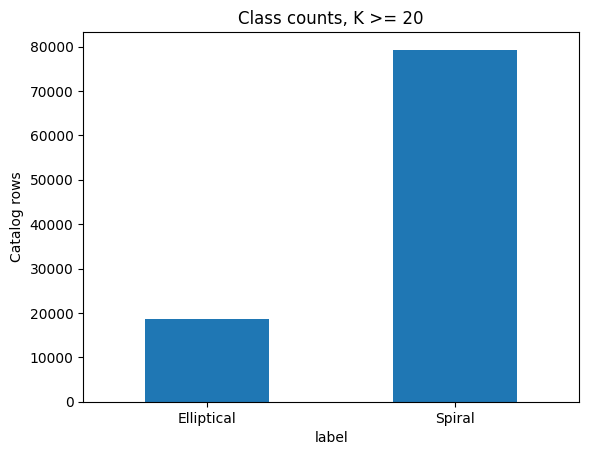

In [5]:
author, _ = read_table(DATA_DIR / AUTHOR_FILE)
zoo, _ = read_table(DATA_DIR / GZ_FILE)
table, audit = select(author, zoo)
sample = table.loc[table[f'selection_k{K_MIN}'].eq('included')].copy().reset_index(drop=True)
if sample.empty or sample.label.nunique() != 2:
    raise ValueError('No usable two-class sample; inspect column mapping and selection counts.')
print('Selection audit:', audit)
print('Independent cuts unavailable:', [c for c in ['z', 'petromag_r', 'b'] if c not in table])
display(sample.groupby('label').size().rename(index=dict(enumerate(CLASSES))).rename('objects').to_frame())
sample.groupby('label').size().rename(index=dict(enumerate(CLASSES))).plot.bar(rot=0, title=f'Class counts, K >= {K_MIN}')
plt.ylabel('Catalog rows'); plt.show()


## 4. Freeze a train/validation/test split
Ten stratified group folds give approximately 80% training, 10% validation, and 10% testing. Groups never cross partitions. All scaling is fitted using training data only. The test fold stays unused until model selection is complete.


In [6]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
fold_id = np.full(len(sample), -1)
for fold, (_, idx) in enumerate(cv.split(sample[list(FEATURES)], sample.label, sample.group_id)):
    fold_id[idx] = fold
train = sample.loc[fold_id >= 2].copy()
val = sample.loc[fold_id == 1].copy()
test = sample.loc[fold_id == 0].copy()
for left, right in [(train, val), (train, test), (val, test)]:
    assert set(left.group_id).isdisjoint(right.group_id)
for part in (train, val, test):
    assert set(part.label) == {0, 1}
assert len(train) + len(val) + len(test) == len(sample)
split_manifest = sample[['row_id', 'objid', 'group_id', 'label']].copy()
split_manifest['split'] = np.where(fold_id == 0, 'test', np.where(fold_id == 1, 'validation', 'train'))
split_manifest.to_csv(OUTPUT_DIR / 'split.csv', index=False)
print({name: len(part) for name, part in [('train', train), ('validation', val), ('test', test)]})
X_train, y_train = train[list(FEATURES)], train.label
X_val, y_val = val[list(FEATURES)], val.label


{'train': 78421, 'validation': 9802, 'test': 9802}


## 5. Train from scratch and select by validation accuracy
Compare the paper’s three classical classifier families: decision tree, RBF SVM, and a ReLU MLP with hidden layers (44, 88, 22). Search settings below are practical choices, not claimed original hyperparameters. A majority-class baseline exposes the effect of class imbalance. Validation macro-F1 breaks accuracy ties. Warnings about MLP convergence remain visible.


In [7]:
experiments = {
    'Decision tree': (DecisionTreeClassifier(random_state=SEED), {'max_depth': [6, 12, None], 'min_samples_leaf': [1, 5]}),
    'SVM': (make_pipeline(StandardScaler(), SVC(kernel='rbf', cache_size=512)), {'svc__C': [1., 10., 100.], 'svc__gamma': ['scale', .1]}),
    'MLP': (make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(44, 88, 22), activation='relu', max_iter=300, random_state=SEED)), {'mlpclassifier__alpha': [.0001, .001]})
}
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Majority validation accuracy:', accuracy_score(y_val, baseline.predict(X_val)))
trials, fitted = [], {}
for family, (base, grid) in experiments.items():
    for params in ParameterGrid(grid):
        started = time.perf_counter()
        model = clone(base).set_params(**params).fit(X_train, y_train)
        pred = model.predict(X_val)
        trial = len(trials)
        fitted[trial] = model
        trials.append(dict(trial=trial, model=family, parameters=params,
                           validation_accuracy=accuracy_score(y_val, pred),
                           validation_macro_f1=f1_score(y_val, pred, average='macro'),
                           seconds=time.perf_counter()-started))
        print(f'{family}: {params}, validation accuracy={trials[-1]["validation_accuracy"]:.4f}', flush=True)
leaderboard = pd.DataFrame(trials).sort_values(['validation_accuracy', 'validation_macro_f1'], ascending=False, kind='stable')
display(leaderboard)
leaderboard.to_csv(OUTPUT_DIR / 'validation_search.csv', index=False)
best_trial = int(leaderboard.iloc[0].trial)
best_model = fitted[best_trial]
print('Selected by validation only:', leaderboard.iloc[0]['model'])


Majority validation accuracy: 0.8117731075290757
Decision tree: {'max_depth': 6, 'min_samples_leaf': 1}, validation accuracy=0.9333
Decision tree: {'max_depth': 6, 'min_samples_leaf': 5}, validation accuracy=0.9334
Decision tree: {'max_depth': 12, 'min_samples_leaf': 1}, validation accuracy=0.9347
Decision tree: {'max_depth': 12, 'min_samples_leaf': 5}, validation accuracy=0.9366
Decision tree: {'max_depth': None, 'min_samples_leaf': 1}, validation accuracy=0.9204
Decision tree: {'max_depth': None, 'min_samples_leaf': 5}, validation accuracy=0.9335
SVM: {'svc__C': 1.0, 'svc__gamma': 'scale'}, validation accuracy=0.8692
SVM: {'svc__C': 1.0, 'svc__gamma': 0.1}, validation accuracy=0.8690
SVM: {'svc__C': 10.0, 'svc__gamma': 'scale'}, validation accuracy=0.8707
SVM: {'svc__C': 10.0, 'svc__gamma': 0.1}, validation accuracy=0.8699
SVM: {'svc__C': 100.0, 'svc__gamma': 'scale'}, validation accuracy=0.8877
SVM: {'svc__C': 100.0, 'svc__gamma': 0.1}, validation accuracy=0.8792
MLP: {'mlpclassifie

,trial,model,parameters,validation_accuracy,validation_macro_f1,seconds
3,3,Decision tree,"{'max_depth': 12, 'min_samples_leaf': 5}",0.936646,0.897844,1.350355
2,2,Decision tree,"{'max_depth': 12, 'min_samples_leaf': 1}",0.934707,0.894825,1.320932
5,5,Decision tree,"{'max_depth': None, 'min_samples_leaf': 5}",0.933483,0.892329,1.581456
1,1,Decision tree,"{'max_depth': 6, 'min_samples_leaf': 5}",0.933381,0.890705,0.875981
0,0,Decision tree,"{'max_depth': 6, 'min_samples_leaf': 1}",0.933279,0.890698,0.778042
13,13,MLP,{'mlpclassifier__alpha': 0.001},0.931443,0.887923,383.142757
12,12,MLP,{'mlpclassifier__alpha': 0.0001},0.928790,0.884543,291.546274
4,4,Decision tree,"{'max_depth': None, 'min_samples_leaf': 1}",0.920424,0.871138,1.644508
10,10,SVM,"{'svc__C': 100.0, 'svc__gamma': 'scale'}",0.887676,0.807799,246.212113
11,11,SVM,"{'svc__C': 100.0, 'svc__gamma': 0.1}",0.879208,0.795011,183.694673


Selected by validation only: Decision tree


## 6. Refit the selected configuration, then evaluate once
The selected configuration is refitted on training plus validation data. Report the resulting test score regardless of its value. Do not rerun seeds or change K to maximize test accuracy. Test performance is not the maximum across candidate models.


{
  "accuracy": 0.9369516425219343,
  "balanced_accuracy": 0.8966184905760844,
  "macro_f1": 0.8980681388634315,
  "majority_accuracy": 0.8078963476841461,
  "test_rows": 9802,
  "K_min": 20,
  "selected_model": "Decision tree"
}
              precision    recall  f1-score   support

  Elliptical     0.8391    0.8311    0.8351      1883
      Spiral     0.9599    0.9621    0.9610      7919

    accuracy                         0.9370      9802
   macro avg     0.8995    0.8966    0.8981      9802
weighted avg     0.9367    0.9370    0.9368      9802



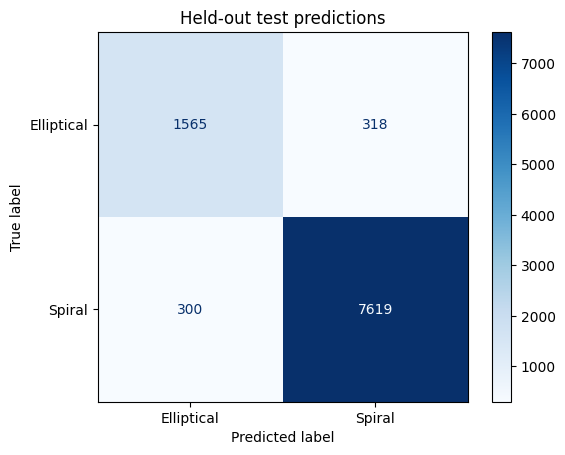

['results\\paper_notebook\\model.joblib']

In [8]:
development = pd.concat([train, val], ignore_index=True)
final_model = clone(best_model).fit(development[list(FEATURES)], development.label)
prediction = final_model.predict(test[list(FEATURES)])
final_baseline = DummyClassifier(strategy='most_frequent').fit(development[list(FEATURES)], development.label)
metrics = {
    'accuracy': accuracy_score(test.label, prediction),
    'balanced_accuracy': balanced_accuracy_score(test.label, prediction),
    'macro_f1': f1_score(test.label, prediction, average='macro'),
    'majority_accuracy': accuracy_score(test.label, final_baseline.predict(test[list(FEATURES)])),
    'test_rows': len(test), 'K_min': K_MIN,
    'selected_model': str(leaderboard.iloc[0]['model']),
}
print(json.dumps(metrics, indent=2))
print(classification_report(test.label, prediction, labels=[0, 1], target_names=CLASSES, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.label, prediction, labels=[0, 1], display_labels=CLASSES, cmap='Blues')
plt.title('Held-out test predictions'); plt.show()
test_output = test[['objid', 'group_id', 'label']].copy()
test_output['prediction'] = prediction
test_output.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
provenance = {'seed': SEED, 'features': FEATURES, 'input_sha256': input_hashes,
              'sklearn_version': sklearn.__version__, 'parameters': trials[best_trial]['parameters'],
              'scope': 'catalog-based classical ML reproduction; no image extraction or CNN', 'metrics': metrics}
(OUTPUT_DIR / 'results.json').write_text(json.dumps(provenance, indent=2))
joblib.dump({'model': final_model, 'features': FEATURES, 'classes': CLASSES, 'provenance': provenance}, OUTPUT_DIR / 'model.joblib')


## 7. Interpret the result honestly
- A result near 98% on this **two-class, K ≥ 20** sample would be comparable in task to Table 3, but not an exact replication of the original experiment.
- Check elliptical recall and macro-F1 alongside overall accuracy; the classes are imbalanced.
- This notebook trains models from scratch using published feature measurements. It does not independently reproduce the paper’s feature extraction or its feature-parameter optimization. Those measurements were optimized in the original study, so this is a conditional evaluation of the released features, not a wholly independent end-to-end validation.
- No original trained classifier or predicted-label column is used as ground truth. GZ1 labels are joined independently.
- If performance is lower, examine catalog match counts, sample selection, schema mapping and convergence using the development data. Preserve the test result.
- To classify a new image, the same CyMorph measurement pipeline must first produce C, A, S, G2, H. This notebook does not accept RGB images as substitutes for those scientific measurements.

**Execution status at delivery:** code cells were syntax-checked. Full training was not run because the two source catalogs and the WSL runtime were unavailable in the authoring session. There are no fabricated result outputs.
